# Lab: generate handwritten digits with a DDPM

**Data:** MNIST · **Images:** 28 × 28 grayscale · **U-Net channels:** 32 / 64 / 128 · **Attention:** none

Train a small convolutional U-Net to predict added Gaussian noise, then generate new digits by
repeatedly denoising fresh noise. Every call to `generate_digits` displays **both the final images
and a noise-to-image trajectory for every generated digit**.

The sequence follows the supplied VAE lab: setup, data, model, objective, training, learning curves,
and generation. Here the model takes a noisy image **and its diffusion timestep**, rather than a
low-dimensional VAE latent vector. Digit labels are never supplied to the model.

**Architecture note.** The original [DDPM paper](https://arxiv.org/abs/2006.11239) used a residual
U-Net with self-attention at 16 × 16. This lab deliberately removes attention and reduces the
width and depth, while keeping residual blocks, GroupNorm, timestep embeddings, and U-Net skips.

**Run guide.** Run cells from top to bottom in Jupyter or Colab. CUDA or Apple MPS is recommended;
CPU is supported but full training is much slower. The default is **30 epochs on 55,000 training
images** and **1,000 diffusion steps**. `QUICK_RUN=True` checks the workflow on a small subset;
it is not a configuration for judging sample quality. Internet access is needed for the first
MNIST download and any missing packages.

This notebook is supplied ready to run, without a completed full-training run or pretrained weights.
It saves checkpoints, metrics, generated images, complete recorded trajectories, and an optional GIF
under a new `outputs/mnist_ddpm_...` directory.


## 1. Setup and experiment settings

Install only missing packages, leaving an existing PyTorch installation unchanged.
PyTorch and torchvision must be a compatible pair; Colab normally supplies both.


In [1]:
import importlib.util
import subprocess
import sys

requirements = {
    'torch': 'torch', 'torchvision': 'torchvision', 'numpy': 'numpy',
    'pandas': 'pandas', 'matplotlib': 'matplotlib', 'tqdm': 'tqdm', 'PIL': 'pillow',
}
missing = [package for module, package in requirements.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
else:
    print('All required packages are available.')


All required packages are available.


In [2]:
import copy
import json
import math
import os
import random
import time
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Image as DisplayImage
from tqdm.auto import tqdm

import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


if torch.cuda.is_available():
    device = torch.device('cuda')
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
    torch.set_num_threads(min(4, os.cpu_count() or 1))

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('PyTorch:', torch.__version__, '| device:', device)


PyTorch: 2.7.0 | device: mps


Use the default model for the main experiment. `BASE_CHANNELS=16` makes a smaller model if memory
or speed is limiting. Quick mode reduces the data and epochs but **keeps the same 1,000-step
noise schedule**. A short linear schedule with unchanged endpoints may leave too much signal
at its final step to justify starting generation from pure Gaussian noise.

`LOAD_CHECKPOINT` skips training and uses weights saved by this notebook. For a new training run,
leave it as `None`. Sampling uses exponential-moving-average (EMA) weights.


In [3]:
SEED = 42
QUICK_RUN = False
IMAGE_SIZE = 28
BASE_CHANNELS = 32
TIME_DIM = 128
DROPOUT = 0.0

T = 1000
BETA_START, BETA_END = 1e-4, 0.02
BATCH_SIZE = 128
LEARNING_RATE = 2e-4
EPOCHS = 2 if QUICK_RUN else 30
EMA_DECAY = 0.999
GRAD_CLIP = 1.0

VAL_SIZE = 5_000
TRAIN_LIMIT = 2_048 if QUICK_RUN else None
EVAL_LIMIT = 256 if QUICK_RUN else None
NUM_WORKERS = 0                    # Portable in notebooks, including Windows/macOS.
SHOW_PROGRESS = True
DATA_ROOT = Path('./data')
DOWNLOAD = True
LOAD_CHECKPOINT = None              # Example: Path('outputs/.../best_ddpm.pt')

NUM_GENERATED = 8
SAMPLE_SEED = 2026
SAVE_GIF = True
CLIP_DENOISED = True
OUTPUT_ROOT = Path('./outputs')
RUN_DIR = OUTPUT_ROOT / f'mnist_ddpm_{datetime.now():%Y%m%d_%H%M%S_%f}'
RUN_DIR.mkdir(parents=True, exist_ok=False)

assert IMAGE_SIZE == 28 and BASE_CHANNELS >= 8 and BASE_CHANNELS % 8 == 0
assert TIME_DIM >= 4 and EPOCHS >= 1 and BATCH_SIZE >= 1
assert T >= 2 and 0 < BETA_START <= BETA_END < 1
assert 0 <= DROPOUT < 1 and 0 <= EMA_DECAY < 1
seed_everything(SEED)
print(f'Channels: {BASE_CHANNELS}, {2*BASE_CHANNELS}, {4*BASE_CHANNELS}; no attention')
print(f'Training: {EPOCHS} epochs | diffusion: {T} steps | quick mode: {QUICK_RUN}')
print('Outputs:', RUN_DIR.resolve())


Channels: 32, 64, 128; no attention
Training: 30 epochs | diffusion: 1000 steps | quick mode: False
Outputs: /Users/xig16121/Desktop/Teaching/Special/code/pytorch/outputs/mnist_ddpm_20261017_221127_833898


## 2. Load MNIST

Split the 60,000 training images into 55,000 training and 5,000 validation images; keep the
10,000 official test images separate. Quick mode takes subsets of these fixed splits.

`ToTensor()` followed by `Normalize((0.5,), (0.5,))` maps pixels from $[0,1]$ to $[-1,1]$.
Images stay **28 × 28**; no resizing, padding, binarization, or digit-flipping augmentation is used.
Each batch has shape `(B, 1, 28, 28)`. The last batch may be smaller than `BATCH_SIZE`.


In [4]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])
mnist_train = datasets.MNIST(DATA_ROOT, train=True, download=DOWNLOAD, transform=transform)
mnist_test = datasets.MNIST(DATA_ROOT, train=False, download=DOWNLOAD, transform=transform)

permutation = torch.randperm(len(mnist_train), generator=torch.Generator().manual_seed(SEED))
val_indices = permutation[:VAL_SIZE].tolist()
train_indices = permutation[VAL_SIZE:].tolist()
if TRAIN_LIMIT is not None:
    train_indices = train_indices[:TRAIN_LIMIT]
if EVAL_LIMIT is not None:
    val_indices = val_indices[:EVAL_LIMIT]

train_data = Subset(mnist_train, train_indices)
val_data = Subset(mnist_train, val_indices)
test_data = (Subset(mnist_test, range(min(EVAL_LIMIT, len(mnist_test))))
             if EVAL_LIMIT is not None else mnist_test)

loader_options = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                      pin_memory=(device.type == 'cuda'))
train_loader = DataLoader(train_data, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED), **loader_options)
val_loader = DataLoader(val_data, shuffle=False, **loader_options)
test_loader = DataLoader(test_data, shuffle=False, **loader_options)
print(f'Train: {len(train_data):,}; validation: {len(val_data):,}; test: {len(test_data):,}')


Train: 55,000; validation: 5,000; test: 10,000


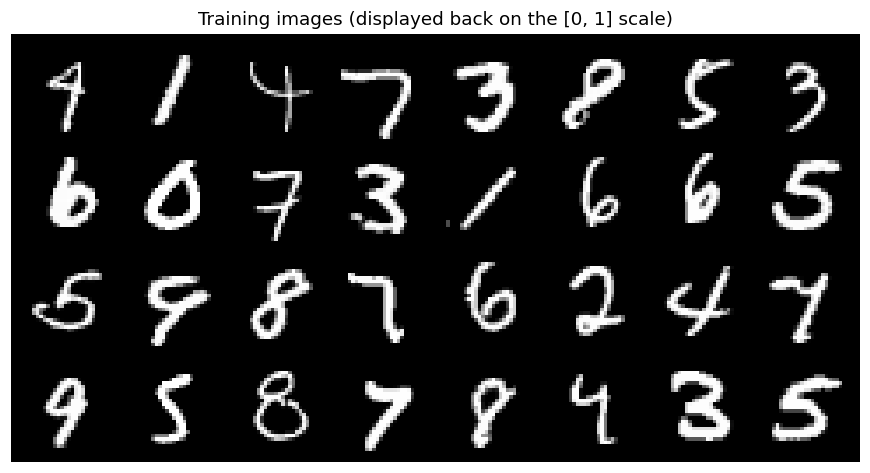

In [5]:
def to_display(images):
    # A fixed intensity scale for every image. This never modifies the sampler's tensors.
    return ((images.detach().cpu() + 1) / 2).clamp(0, 1)


def show_digits(images, title, nrow=8, filename=None):
    grid = make_grid(to_display(images), nrow=nrow, padding=2, pad_value=0)
    fig, ax = plt.subplots(figsize=(min(10, nrow * 1.1), max(2, math.ceil(len(images)/nrow)*1.1)))
    ax.imshow(grid.permute(1, 2, 0).numpy(), vmin=0, vmax=1)
    ax.set(title=title)
    ax.axis('off')
    fig.tight_layout()
    if filename is not None:
        fig.savefig(filename, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)


def show_trajectories(states, steps, title, prefix=None, rows_per_figure=8):
    """states: (number of saved times, number of images, 1, H, W). Every image gets a row."""
    assert states.ndim == 5 and len(states) == len(steps)
    images = to_display(states)
    n_images = states.shape[1]
    for start in range(0, n_images, rows_per_figure):
        end = min(start + rows_per_figure, n_images)
        fig, axes = plt.subplots(end-start, len(steps), squeeze=False,
                                 figsize=(1.15*len(steps), 1.15*(end-start)+0.65))
        for row, sample_id in enumerate(range(start, end)):
            for col, step in enumerate(steps):
                ax = axes[row, col]
                ax.imshow(images[col, sample_id, 0], cmap='gray', vmin=0, vmax=1)
                ax.set_xticks([]); ax.set_yticks([])
                for spine in ax.spines.values():
                    spine.set_visible(False)
                if row == 0:
                    ax.set_title(f't = {step}')
                if col == 0:
                    ax.set_ylabel(f'Image {sample_id+1}')
        fig.suptitle(title, y=1.01)
        fig.tight_layout()
        if prefix is not None:
            fig.savefig(f'{prefix}_{start+1:02d}-{end:02d}.png', dpi=160, bbox_inches='tight')
        plt.show()
        plt.close(fig)


show_digits(torch.stack([train_data[i][0] for i in range(32)]),
            'Training images (displayed back on the [0, 1] scale)',
            filename=RUN_DIR / 'training_examples.png')


## 3. Forward diffusion and the noise schedule

We use **mathematical timestep labels throughout the code**: $x_0$ is clean, and
$t=1,\ldots,T$ are noisy states. Schedule arrays have length $T+1$, with a dummy entry
$\beta_0=0$ and $\bar\alpha_0=1$. Thus `states[0]` in a returned trajectory is its first
saved state, whereas `steps[0]` tells you that state's actual diffusion time.

For $\alpha_t=1-\beta_t$ and $\bar\alpha_t=\prod_{s=1}^t\alpha_s$,
$$
x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon,
\qquad \epsilon\sim\mathcal N(0,I_{784}).
$$
One direct draw is enough for training; we do not simulate all earlier forward steps.
`extract` turns a batch of timestep indices into coefficients of shape `(B,1,1,1)` so
PyTorch can broadcast them across image channels and pixels.


In [6]:
class DiffusionSchedule(nn.Module):
    def __init__(self, steps=1000, beta_start=1e-4, beta_end=0.02):
        super().__init__()
        self.steps = steps
        # Compute coefficients in float64, then store float32 for model calculations.
        beta = torch.cat([torch.zeros(1, dtype=torch.float64),
                          torch.linspace(beta_start, beta_end, steps, dtype=torch.float64)])
        alpha = 1 - beta
        alpha_bar = alpha.cumprod(dim=0)
        alpha_bar_prev = torch.cat([torch.ones(1, dtype=torch.float64), alpha_bar[:-1]])
        denominator = (1 - alpha_bar).clamp_min(1e-20)
        values = {
            'beta': beta, 'alpha': alpha, 'alpha_bar': alpha_bar,
            'sqrt_alpha_bar': alpha_bar.sqrt(),
            'sqrt_one_minus_alpha_bar': (1 - alpha_bar).sqrt(),
            'posterior_variance': beta * (1 - alpha_bar_prev) / denominator,
            'posterior_coef_x0': beta * alpha_bar_prev.sqrt() / denominator,
            'posterior_coef_xt': alpha.sqrt() * (1 - alpha_bar_prev) / denominator,
        }
        for name, value in values.items():
            self.register_buffer(name, value.float())

    def extract(self, name, t):
        return getattr(self, name)[t].view(-1, 1, 1, 1)

    def q_sample(self, x0, t, noise=None):
        if noise is None:
            noise = torch.randn_like(x0)
        return (self.extract('sqrt_alpha_bar', t) * x0
                + self.extract('sqrt_one_minus_alpha_bar', t) * noise)


diffusion = DiffusionSchedule(T, BETA_START, BETA_END).to(device)
print(f'alpha_bar[T] = {diffusion.alpha_bar[-1].item():.6g}')
print(f'Remaining signal coefficient = {diffusion.sqrt_alpha_bar[-1].item():.6g}')


alpha_bar[T] = 4.03583e-05
Remaining signal coefficient = 0.00635282


The next figure illustrates the forward marginals using the **same noise draw** at different
timesteps to make the progression easy to see. These are not consecutive states of a sampled
forward Markov chain. The generation figure later records a genuine reverse sampling trajectory.


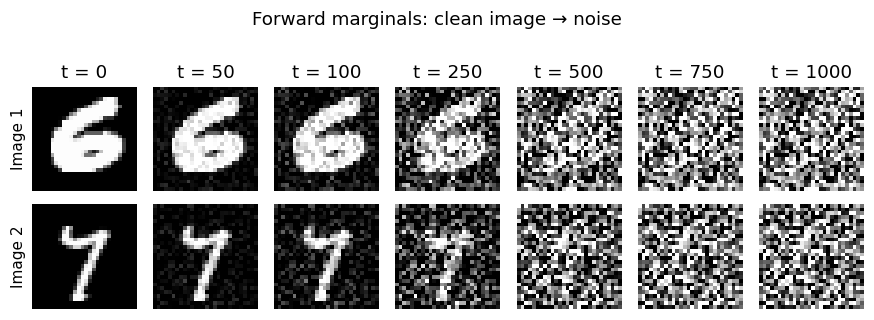

In [7]:
forward_steps = sorted(set([0, T//20, T//10, T//4, T//2, 3*T//4, T]))
x0_examples = torch.stack([val_data[i][0] for i in range(2)]).to(device)
noise = torch.randn(x0_examples.shape, generator=torch.Generator().manual_seed(SEED+1)).to(device)
with torch.inference_mode():
    forward_states = torch.stack([
        diffusion.q_sample(x0_examples, torch.full((2,), t, device=device, dtype=torch.long), noise).cpu()
        for t in forward_steps
    ])
show_trajectories(forward_states, forward_steps, 'Forward marginals: clean image → noise',
                  prefix=RUN_DIR / 'forward')


## 4. A small, attention-free residual U-Net

The model implements $\epsilon_\theta(x_t,t)$ and returns a tensor with the **same shape as the
input image**. The output is an unrestricted real-valued noise prediction, so there is no
sigmoid or tanh output activation.

| Stage | Feature shape, excluding batch | Operations |
|:--|:--|:--|
| Input stem | 32 × 28 × 28 | 3 × 3 convolution |
| Encoder level 1 | 32 × 28 × 28 | 2 residual blocks; save skip |
| Downsample | 64 × 14 × 14 | Stride-2 convolution |
| Encoder level 2 | 64 × 14 × 14 | 2 residual blocks; save skip |
| Downsample | 128 × 7 × 7 | Stride-2 convolution |
| Bottleneck | 128 × 7 × 7 | 2 residual blocks |
| Decoder level 2 | 64 × 14 × 14 | Upsample, concatenate 64-channel skip, 2 residual blocks |
| Decoder level 1 | 32 × 28 × 28 | Upsample, concatenate 32-channel skip, 2 residual blocks |
| Output | 1 × 28 × 28 | GroupNorm, SiLU, 3 × 3 convolution |

The table uses `BASE_CHANNELS=32`; all widths scale with that setting. Downsampling uses
3 × 3 stride-2 convolutions with padding 1. Upsampling uses nearest-neighbor resizing followed by a
3 × 3 convolution. Skip connections **concatenate channels**, while the short connection
inside each residual block **adds** its input (projected by 1 × 1 convolution when needed).

**Time conditioning.** A fixed sinusoidal encoding of $t$ passes through a learned MLP. Each
residual block projects the resulting vector to its output channel count and adds it to the
feature map. This gives one shared network information about the current noise level.


In [8]:
def group_norm(channels):
    groups = next(g for g in (8, 4, 2, 1) if channels % g == 0)
    return nn.GroupNorm(groups, channels)


class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        assert dim >= 4 and dim % 2 == 0
        half = dim // 2
        frequencies = torch.exp(-math.log(10000) * torch.arange(half) / (half - 1))
        self.register_buffer('frequencies', frequencies)

    def forward(self, t):
        angles = t.float()[:, None] * self.frequencies[None, :]
        return torch.cat([angles.sin(), angles.cos()], dim=-1)


class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim, dropout=0.0):
        super().__init__()
        self.norm1 = group_norm(in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.time_projection = nn.Linear(time_dim, out_channels)
        self.norm2 = group_norm(out_channels)
        self.dropout = nn.Dropout(dropout)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.skip = (nn.Identity() if in_channels == out_channels
                     else nn.Conv2d(in_channels, out_channels, 1))

    def forward(self, x, time_embedding):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time_projection(F.silu(time_embedding))[:, :, None, None]
        h = self.conv2(self.dropout(F.silu(self.norm2(h))))
        return h + self.skip(x)


In [9]:
class SmallUNet(nn.Module):
    def __init__(self, base_channels=32, time_dim=128, dropout=0.0):
        super().__init__()
        c = base_channels
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(c), nn.Linear(c, time_dim), nn.SiLU(),
            nn.Linear(time_dim, time_dim),
        )
        self.stem = nn.Conv2d(1, c, 3, padding=1)
        self.enc28 = nn.ModuleList([ResidualBlock(c, c, time_dim, dropout) for _ in range(2)])
        self.down28 = nn.Conv2d(c, 2*c, 3, stride=2, padding=1)
        self.enc14 = nn.ModuleList([ResidualBlock(2*c, 2*c, time_dim, dropout) for _ in range(2)])
        self.down14 = nn.Conv2d(2*c, 4*c, 3, stride=2, padding=1)
        self.middle = nn.ModuleList([ResidualBlock(4*c, 4*c, time_dim, dropout) for _ in range(2)])
        self.up14 = nn.Conv2d(4*c, 2*c, 3, padding=1)
        self.dec14 = nn.ModuleList([
            ResidualBlock(4*c, 2*c, time_dim, dropout),
            ResidualBlock(2*c, 2*c, time_dim, dropout),
        ])
        self.up28 = nn.Conv2d(2*c, c, 3, padding=1)
        self.dec28 = nn.ModuleList([
            ResidualBlock(2*c, c, time_dim, dropout),
            ResidualBlock(c, c, time_dim, dropout),
        ])
        self.output = nn.Sequential(group_norm(c), nn.SiLU(), nn.Conv2d(c, 1, 3, padding=1))
        # Start close to the simple zero-noise predictor.
        nn.init.zeros_(self.output[-1].weight)
        nn.init.zeros_(self.output[-1].bias)

    @staticmethod
    def apply_blocks(blocks, x, embedding):
        for block in blocks:
            x = block(x, embedding)
        return x

    def forward(self, x, t):
        embedding = self.time_mlp(t)
        skip28 = self.apply_blocks(self.enc28, self.stem(x), embedding)
        skip14 = self.apply_blocks(self.enc14, self.down28(skip28), embedding)
        h = self.apply_blocks(self.middle, self.down14(skip14), embedding)
        h = self.up14(F.interpolate(h, size=skip14.shape[-2:], mode='nearest'))
        h = self.apply_blocks(self.dec14, torch.cat([h, skip14], dim=1), embedding)
        h = self.up28(F.interpolate(h, size=skip28.shape[-2:], mode='nearest'))
        h = self.apply_blocks(self.dec28, torch.cat([h, skip28], dim=1), embedding)
        return self.output(h)


In [10]:
seed_everything(SEED)
model = SmallUNet(BASE_CHANNELS, TIME_DIM, DROPOUT).to(device)
ema_model = copy.deepcopy(model).eval().requires_grad_(False)

model.eval()
with torch.inference_mode():
    dummy_x = torch.randn(2, 1, IMAGE_SIZE, IMAGE_SIZE, device=device)
    dummy_t = torch.tensor([1, T], dtype=torch.long, device=device)
    dummy_output = model(dummy_x, dummy_t)
assert dummy_output.shape == dummy_x.shape
assert torch.isfinite(dummy_output).all()
print('Input/output:', tuple(dummy_output.shape))
print(f'Trainable parameters: {sum(p.numel() for p in model.parameters()):,}')
print('Residual blocks:', sum(isinstance(m, ResidualBlock) for m in model.modules()))
print('Attention modules: 0')
del dummy_x, dummy_t, dummy_output


Input/output: (2, 1, 28, 28)
Trainable parameters: 1,307,489
Residual blocks: 10
Attention modules: 0


## 5. Minibatch training objective and EMA

For every image in a minibatch, independently draw $t_i\sim\mathrm{Uniform}\{1,\ldots,T\}$
and $\epsilon_i\sim\mathcal N(0,I_{784})$, then construct $x_{t_i}$ directly. The loss is
$$
\widehat{\mathcal L}_{\mathrm{simple}}(\theta)
=\frac{1}{B\cdot784}\sum_{i=1}^{B}
\left\|\epsilon_i-\epsilon_\theta(x_{t_i},t_i)\right\|_2^2.
$$
`F.mse_loss` averages over the batch and pixels. Compared with the usual squared-norm
expression, this introduces only the constant factor $1/784$.

`model.train()` enables dropout if requested; `model.eval()` disables it during evaluation
and generation. EMA maintains a smoothed parameter copy for evaluation and sampling, using
$\theta_{\rm EMA}\leftarrow d\theta_{\rm EMA}+(1-d)\theta$ after each optimizer step. A short
warm-up of $d$ prevents the EMA from retaining too much of the initialization early in training.


In [11]:
@torch.no_grad()
def update_ema(ema_model, model, global_step):
    decay = min(EMA_DECAY, (1 + global_step) / (10 + global_step))
    for ema_parameter, parameter in zip(ema_model.parameters(), model.parameters()):
        ema_parameter.lerp_(parameter, 1 - decay)
    for ema_buffer, buffer in zip(ema_model.buffers(), model.buffers()):
        ema_buffer.copy_(buffer)


def train_one_epoch(model, ema_model, loader, optimizer, diffusion, epoch, global_step):
    model.train()
    total_loss, count = 0.0, 0
    batches = tqdm(loader, desc=f'Epoch {epoch}', leave=False, disable=not SHOW_PROGRESS)
    for x0, _ in batches:                   # Digit labels are intentionally unused.
        x0 = x0.to(device, non_blocking=(device.type == 'cuda'))
        t = torch.randint(1, diffusion.steps + 1, (len(x0),), device=device)
        noise = torch.randn_like(x0)
        xt = diffusion.q_sample(x0, t, noise)
        optimizer.zero_grad(set_to_none=True)
        predicted_noise = model(xt, t)
        loss = F.mse_loss(predicted_noise, noise)
        if not torch.isfinite(loss):
            raise FloatingPointError('Non-finite loss. Check the data and learning rate.')
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP, error_if_nonfinite=True)
        optimizer.step()
        global_step += 1
        update_ema(ema_model, model, global_step)
        total_loss += loss.detach().item() * len(x0)
        count += len(x0)
        batches.set_postfix(mse=f'{total_loss/count:.4f}')
    return total_loss / count, global_step


@torch.inference_mode()
def evaluate_noise_mse(model, loader, diffusion, seed=1001):
    was_training = model.training
    model.eval()
    # Local CPU RNG makes repeated validation use the same t/noise and works with MPS.
    generator = torch.Generator(device='cpu').manual_seed(seed)
    model_device = next(model.parameters()).device
    total_loss, count = 0.0, 0
    try:
        for x0, _ in loader:
            t = torch.randint(1, diffusion.steps + 1, (len(x0),), generator=generator).to(model_device)
            noise = torch.randn(x0.shape, generator=generator).to(model_device)
            x0 = x0.to(model_device)
            xt = diffusion.q_sample(x0, t, noise)
            loss = F.mse_loss(model(xt, t), noise)
            total_loss += loss.item() * len(x0)
            count += len(x0)
    finally:
        model.train(was_training)
    result = total_loss / count
    if not math.isfinite(result):
        raise FloatingPointError('Non-finite evaluation loss.')
    return result


## 6. Train and save checkpoints

Choose the checkpoint with the lowest **EMA validation noise-prediction MSE**. This is a
held-out denoising metric, not a direct score of perceptual sample quality. Compare generated
images too. Training loss uses the current model; validation uses the EMA model.

`best_ddpm.pt` stores the selected raw/EMA weights and their configuration. `last_ddpm.pt`
stores the most recent epoch. Set `LOAD_CHECKPOINT` to either file to skip training and generate
from it. Changing the architecture or noise schedule requires a matching checkpoint.


In [12]:
run_config = {
    'architecture': 'small_residual_unet_v1', 'attention': False,
    'image_size': IMAGE_SIZE, 'input_range': [-1, 1],
    'base_channels': BASE_CHANNELS, 'time_dim': TIME_DIM, 'dropout': DROPOUT,
    'T': T, 'beta_start': BETA_START, 'beta_end': BETA_END,
    'reverse_variance': 'posterior', 'clip_denoised': CLIP_DENOISED,
    'seed': SEED, 'batch_size': BATCH_SIZE, 'learning_rate': LEARNING_RATE,
    'ema_decay': EMA_DECAY, 'epochs_requested': EPOCHS, 'quick_run': QUICK_RUN,
    'train_size': len(train_data), 'val_size': len(val_data), 'test_size': len(test_data),
    'torch_version': str(torch.__version__), 'device': str(device),
}
(RUN_DIR / 'config.json').write_text(json.dumps(run_config, indent=2))


def load_matching_checkpoint(path):
    checkpoint = torch.load(Path(path), map_location='cpu', weights_only=True)
    required = ('architecture', 'image_size', 'input_range', 'base_channels', 'time_dim',
                'dropout', 'T', 'beta_start', 'beta_end', 'reverse_variance')
    mismatches = [key for key in required if checkpoint['config'].get(key) != run_config[key]]
    if mismatches:
        raise ValueError(f'Match these settings to the checkpoint, then rerun setup: {mismatches}')
    model.load_state_dict(checkpoint['model_state'])
    ema_model.load_state_dict(checkpoint['ema_state'])
    model.to(device)
    ema_model.to(device).eval()
    return checkpoint


if LOAD_CHECKPOINT is not None:
    best_checkpoint = Path(LOAD_CHECKPOINT)
    checkpoint = load_matching_checkpoint(best_checkpoint)
    history_df = pd.DataFrame(checkpoint['history'])
    print(f'Loaded epoch {checkpoint["epoch"]}; no new training performed.')
else:
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history, global_step = [], 0
    best_val = float('inf')
    best_checkpoint = RUN_DIR / 'best_ddpm.pt'
    for epoch in range(1, EPOCHS + 1):
        started = time.perf_counter()
        train_mse, global_step = train_one_epoch(
            model, ema_model, train_loader, optimizer, diffusion, epoch, global_step)
        val_mse = evaluate_noise_mse(ema_model, val_loader, diffusion, seed=1001)
        row = {'epoch': epoch, 'global_step': global_step, 'train_mse': train_mse,
               'val_ema_mse': val_mse, 'seconds': time.perf_counter()-started}
        history.append(row)
        checkpoint = {
            'model_state': model.state_dict(), 'ema_state': ema_model.state_dict(),
            'config': run_config, 'epoch': epoch, 'global_step': global_step,
            'val_ema_mse': val_mse, 'history': list(history),
        }
        if val_mse < best_val:
            best_val = val_mse
            torch.save(checkpoint, best_checkpoint)
        torch.save(checkpoint, RUN_DIR / 'last_ddpm.pt')
        history_df = pd.DataFrame(history)
        history_df.to_csv(RUN_DIR / 'history.csv', index=False)
        print(f'Epoch {epoch:02d}/{EPOCHS} | train MSE {train_mse:.5f}'
              f' | validation EMA MSE {val_mse:.5f} | {row["seconds"]:.1f}s', flush=True)
    print('Best checkpoint:', best_checkpoint.resolve())

history_df.to_csv(RUN_DIR / 'history.csv', index=False)
selected_checkpoint = load_matching_checkpoint(best_checkpoint)
print(f'Selected epoch: {selected_checkpoint["epoch"]}')


Epoch 1:   0%|          | 0/430 [00:00<?, ?it/s]

Epoch 01/30 | train MSE 0.12522 | validation EMA MSE 0.03377 | 56.7s


Epoch 2:   0%|          | 0/430 [00:00<?, ?it/s]

Epoch 02/30 | train MSE 0.03127 | validation EMA MSE 0.02905 | 54.6s


Epoch 3:   0%|          | 0/430 [00:00<?, ?it/s]

...

Epoch 28/30 | train MSE 0.02251 | validation EMA MSE 0.02175 | 56.3s


Epoch 29:   0%|          | 0/430 [00:00<?, ?it/s]

Epoch 29/30 | train MSE 0.02228 | validation EMA MSE 0.02171 | 58.0s


Epoch 30:   0%|          | 0/430 [00:00<?, ?it/s]

Epoch 30/30 | train MSE 0.02230 | validation EMA MSE 0.02167 | 56.6s
Best checkpoint: /Users/xig16121/Desktop/Teaching/Special/code/pytorch/outputs/mnist_ddpm_20261017_221127_833898/best_ddpm.pt
Selected epoch: 30


## 7. Learning curves and held-out noise prediction

A predictor that always returns zero has expected noise MSE 1. Lower MSE indicates better
noise prediction averaged over timesteps; it does not by itself establish good digit generation.
The official test set is evaluated only after selecting a checkpoint using validation data.


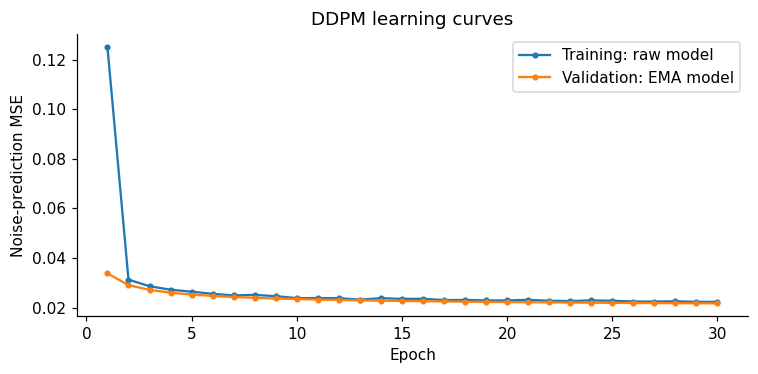

Held-out test noise MSE (EMA): 0.02179


In [13]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(history_df['epoch'], history_df['train_mse'], marker='.', label='Training: raw model')
ax.plot(history_df['epoch'], history_df['val_ema_mse'], marker='.', label='Validation: EMA model')
ax.set(xlabel='Epoch', ylabel='Noise-prediction MSE', title='DDPM learning curves')
ax.legend()
fig.tight_layout()
fig.savefig(RUN_DIR / 'learning_curves.png', dpi=160, bbox_inches='tight')
plt.show(); plt.close(fig)

test_mse = evaluate_noise_mse(ema_model, test_loader, diffusion, seed=2002)
test_summary = {'selected_epoch': selected_checkpoint['epoch'], 'test_noise_mse': test_mse,
                'test_size': len(test_data)}
(RUN_DIR / 'test_metrics.json').write_text(json.dumps(test_summary, indent=2))
print(f'Held-out test noise MSE (EMA): {test_mse:.5f}')


## 8. Reverse diffusion: fresh noise to new digits

Start with $x_T\sim\mathcal N(0,I_{784})$. At time $t$, predict noise and estimate the clean image:
$$
\widehat x_0=\frac{x_t-\sqrt{1-\bar\alpha_t}\,\epsilon_\theta(x_t,t)}{\sqrt{\bar\alpha_t}}.
$$
We optionally clip **this clean-image estimate** to $[-1,1]$, then use the DDPM posterior coefficients:
$$
\mu_\theta(x_t,t)=
\frac{\beta_t\sqrt{\bar\alpha_{t-1}}}{1-\bar\alpha_t}\widehat x_0
+\frac{\sqrt{\alpha_t}(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}x_t,
\qquad
\widetilde\beta_t=\beta_t\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}.
$$
For $t>1$, sample $x_{t-1}=\mu_\theta(x_t,t)+\sqrt{\widetilde\beta_t}\,z$ with fresh
$z\sim\mathcal N(0,I)$. At **$t=1$, add no noise**. This uses the fixed posterior-variance
choice $\sigma_t^2=\widetilde\beta_t$ discussed in the DDPM paper.

Without clean-estimate clipping, this mean equals the familiar epsilon form
$\alpha_t^{-1/2}\{x_t-\beta_t\epsilon_\theta(x_t,t)/\sqrt{1-\bar\alpha_t}\}$.
The notebook uses all $T$ adjacent reverse steps; saving fewer snapshots does not skip sampling steps.

The recorded columns are actual $x_t$ states from **the same reverse trajectory**. After a step
from $t$ to $t-1$, its result is labeled $t-1$. We preserve the initial pure-noise state and the
final $x_0$. Display clipping affects the figure only; intermediate sampler states stay unclipped.


In [14]:
def default_snapshot_steps(T):
    fractions = [1, 0.8, 0.6, 0.4, 0.2, 0.1, 0.05, 0.02, 0.01, 0]
    return sorted({round(T * fraction) for fraction in fractions}, reverse=True)


@torch.inference_mode()
def sample_ddpm(model, diffusion, n_samples=8, seed=2026, snapshot_steps=None,
                clip_denoised=True, show_progress=True):
    if n_samples < 1:
        raise ValueError('n_samples must be positive.')
    model_device = next(model.parameters()).device
    if diffusion.beta.device != model_device:
        raise ValueError('Move the model and diffusion schedule to the same device.')
    T = diffusion.steps
    steps = default_snapshot_steps(T) if snapshot_steps is None else list(snapshot_steps)
    if any(not isinstance(s, (int, np.integer)) or not 0 <= s <= T for s in steps):
        raise ValueError('Snapshot times must be integers between 0 and T.')
    steps = sorted(set([int(s) for s in steps] + [T, 0]), reverse=True)
    generator = torch.Generator(device='cpu').manual_seed(seed)
    shape = (n_samples, 1, IMAGE_SIZE, IMAGE_SIZE)
    x = torch.randn(shape, generator=generator).to(model_device)   # x_T
    saved = {T: x.cpu().clone()}
    was_training = model.training
    model.eval()
    try:
        for time_step in tqdm(range(T, 0, -1), total=T, desc='DDPM generation',
                              leave=False, disable=not show_progress):
            t = torch.full((n_samples,), time_step, device=model_device, dtype=torch.long)
            predicted_noise = model(x, t)
            x0_hat = ((x - diffusion.extract('sqrt_one_minus_alpha_bar', t) * predicted_noise)
                      / diffusion.extract('sqrt_alpha_bar', t))
            if clip_denoised:
                x0_hat = x0_hat.clamp(-1, 1)
            mean = (diffusion.extract('posterior_coef_x0', t) * x0_hat
                    + diffusion.extract('posterior_coef_xt', t) * x)
            if time_step > 1:
                noise = torch.randn(shape, generator=generator).to(model_device)
                x = mean + diffusion.extract('posterior_variance', t).sqrt() * noise
            else:
                x = mean                                # x_0; no additional noise.
            state_time = time_step - 1
            if state_time in steps:
                saved[state_time] = x.cpu().clone()
        states = torch.stack([saved[t] for t in steps])
        if not torch.isfinite(states).all():
            raise FloatingPointError('Non-finite sampled values. Inspect training and the schedule.')
        return {'samples': x.cpu(), 'states': states, 'steps': steps, 'seed': int(seed)}
    finally:
        model.train(was_training)


## 9. Generate and inspect every digit's trajectory

Each row follows one sample through time; the last column matches its final generated image.
The fixed display mapping is `(x + 1) / 2`, clipped to `[0,1]`, so noisy values outside that range
saturate only in the visualization. No per-image contrast normalization is used.

The optional GIF animates the saved snapshots with a longer pause on the final images; frames
are not equally spaced in diffusion time. Raw saved states and their exact timestep labels are
also written to a compressed NumPy file. Change `seed` to generate a new batch; repeating a seed
repeats the initial and subsequent sampling noise on the same setup.


DDPM generation:   0%|          | 0/1000 [00:00<?, ?it/s]

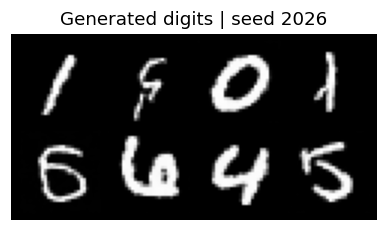

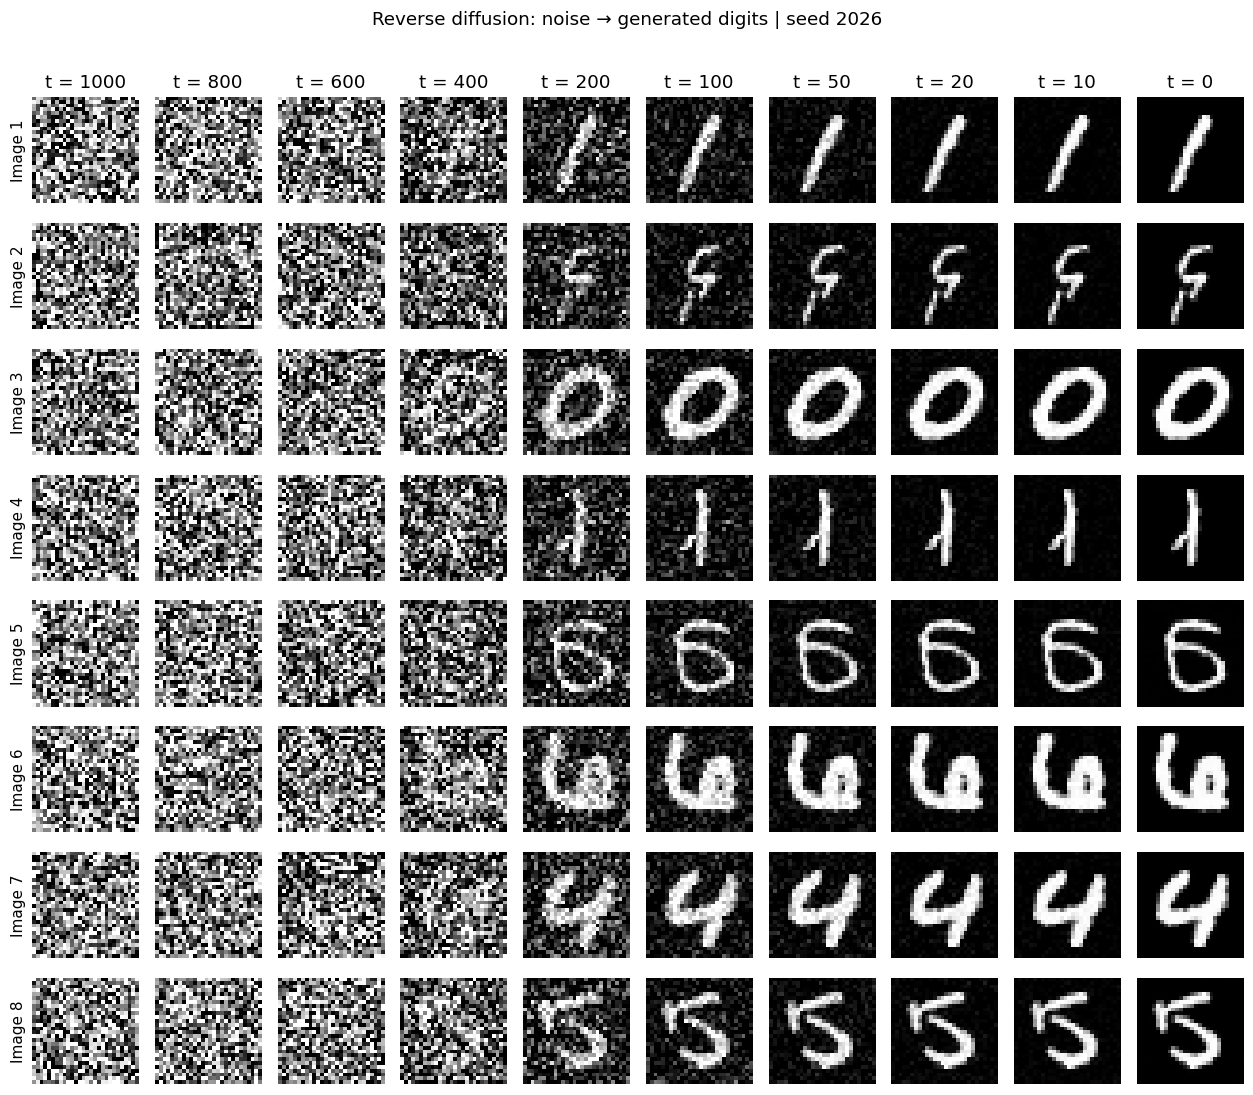

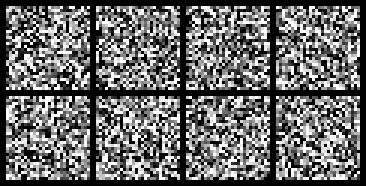

Saved generation: generation_seed2026_224615_824745


In [15]:
def save_trajectory_gif(result, path, nrow=4, scale=3):
    frames = []
    for state in result['states']:
        grid = make_grid(to_display(state), nrow=min(nrow, len(state)), padding=2, pad_value=0)
        array = (grid.permute(1, 2, 0).numpy() * 255).round().astype(np.uint8)
        frame = Image.fromarray(array)
        frame = frame.resize((frame.width * scale, frame.height * scale), resample=Image.Resampling.NEAREST)
        frames.append(frame)
    durations = [300] * len(frames)
    durations[-1] = 1200
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=durations, loop=0)


def generate_digits(model, diffusion, n_samples=8, seed=2026, save_gif=True,
                    clip_denoised=True, show_progress=True):
    result = sample_ddpm(model, diffusion, n_samples=n_samples, seed=seed,
                         clip_denoised=clip_denoised, show_progress=show_progress)
    tag = f'generation_seed{seed}_{datetime.now():%H%M%S_%f}'
    save_image(to_display(result['samples']), RUN_DIR / f'{tag}_digits.png',
               nrow=min(4, n_samples), padding=2, pad_value=0)
    np.savez_compressed(RUN_DIR / f'{tag}_trajectory.npz',
                        states=result['states'].numpy(), steps=np.array(result['steps']), seed=seed)
    show_digits(result['samples'], f'Generated digits | seed {seed}', nrow=min(4, n_samples))
    show_trajectories(result['states'], result['steps'],
                      f'Reverse diffusion: noise → generated digits | seed {seed}',
                      prefix=RUN_DIR / f'{tag}_trajectory')
    if save_gif:
        gif_path = RUN_DIR / f'{tag}.gif'
        save_trajectory_gif(result, gif_path)
        display(DisplayImage(filename=str(gif_path)))
    print('Saved generation:', tag)
    return result


if QUICK_RUN:
    print('Quick-run model: this checks execution, not final digit quality.')
generated = generate_digits(
    ema_model, diffusion, n_samples=NUM_GENERATED, seed=SAMPLE_SEED,
    save_gif=SAVE_GIF, clip_denoised=CLIP_DENOISED, show_progress=SHOW_PROGRESS,
)


In [16]:
# Generate another independent batch whenever you like. Every call also shows its trajectories.
# new_batch = generate_digits(ema_model, diffusion, n_samples=8, seed=2027,
#                             save_gif=True, clip_denoised=CLIP_DENOISED)

# Access the raw tensors and timestep labels from the previous call:
print('Final samples:', tuple(generated['samples'].shape))
print('Saved trajectory:', tuple(generated['states'].shape))
print('Saved times:', generated['steps'])
assert generated['steps'][0] == T and generated['steps'][-1] == 0
assert torch.equal(generated['samples'], generated['states'][-1])


Final samples: (8, 1, 28, 28)
Saved trajectory: (10, 8, 1, 28, 28)
Saved times: [1000, 800, 600, 400, 200, 100, 50, 20, 10, 0]


## 10. Reuse trained weights later

The simplest route is to set `LOAD_CHECKPOINT` in the settings cell and rerun the notebook;
the training loop will be skipped. The helper below also rebuilds the model and schedule directly
from a checkpoint's metadata. For a generation-only session, run the setup/import, model,
schedule, plotting, and sampling definitions, then use this helper; no MNIST download is needed.


In [17]:
def load_trained_ddpm(path, target_device=device):
    checkpoint = torch.load(Path(path), map_location='cpu', weights_only=True)
    config = checkpoint['config']
    if config.get('architecture') != 'small_residual_unet_v1' or config['image_size'] != 28:
        raise ValueError("This helper expects a 28×28 residual U-Net from this notebook.")
    restored_model = SmallUNet(config['base_channels'], config['time_dim'], config['dropout'])
    restored_model.load_state_dict(checkpoint['ema_state'])
    restored_model = restored_model.to(target_device).eval().requires_grad_(False)
    restored_diffusion = DiffusionSchedule(config['T'], config['beta_start'], config['beta_end'])
    return restored_model, restored_diffusion.to(target_device), config


# Example (uncomment and replace the path):
# restored_model, restored_diffusion, saved_config = load_trained_ddpm('outputs/.../best_ddpm.pt')
# restored_samples = generate_digits(restored_model, restored_diffusion, n_samples=8, seed=2028,
#                                     clip_denoised=saved_config['clip_denoised'])


## Lab notes and useful experiments

- **Training versus generation:** one random timestep per image per training update; all 1,000
  reverse steps per generated image. The same U-Net weights are shared across timesteps.
- **Time conditioning is essential:** the model needs to know which corruption level it is removing.
  The target is the Gaussian noise tensor, not a digit label or the original clean image.
- **Two kinds of skip:** U-Net skips concatenate encoder features; residual skips add a block's input.
- **If samples are weak:** first check that `QUICK_RUN=False`, normalization is `[-1,1]`, and the
  loaded checkpoint matches the model and schedule. Train longer and compare new trajectories.
- **If memory is limited:** reduce `BATCH_SIZE` first. A smaller `BASE_CHANNELS` changes the model
  and requires retraining. CPU support does not imply that full training or 1,000-step sampling is fast.
- **Controlled comparisons:** hold the sampling seed fixed when comparing two checkpoints. Seeds
  improve reproducibility, but results may differ across hardware and library versions.
- **Optional experiment:** compare widths 16 and 32 using the same data split, training budget,
  validation noise, and sampling seeds. Attention is absent from both models.

### References

- Ho, Jain, and Abbeel (2020), [Denoising Diffusion Probabilistic Models](https://arxiv.org/abs/2006.11239):
  noise-prediction training, reverse Gaussian sampling, and the residual U-Net design.
- [Authors' diffusion implementation](https://github.com/hojonathanho/diffusion):
  posterior coefficients and clipping of the predicted clean image.
- [PyTorch MNIST dataset](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html)
  and [GroupNorm](https://docs.pytorch.org/docs/stable/generated/torch.nn.GroupNorm.html).

This is a compact teaching implementation, not a reproduction of the paper's full architecture
or reported benchmarks. The supplied VAE notebook guided the lab's presentation and workflow.
